# Pràctica II - Perceptron amb Scikit-learn

En la sessió anterior hem implementat i entrenat un perceptró des de zero, analitzant pas a pas el seu funcionament intern. Ara, donarem un pas més i treballarem amb la implementació ja disponible a la llibreria `scikit-learn`que ens permetrà concentrar-nos en el procés d'aplicació del model a un conjunt de dades real, i l'ampliarem amb un model més potent: el *Multi-Layer Perceptron*.

Per tal d’il·lustrar-ho, farem servir el problema del Titanic, que ja coneixeu del curs anterior. L’objectiu és predir si un passatger va sobreviure o no al naufragi a partir d’algunes de les seves característiques (edat, sexe, classe del bitllet, etc.).

Tasques a realitzar:

1. Carregar i preparar les dades
   - Importar el conjunt de dades del Titanic.
   - Seleccionar les variables més rellevants i realitzar els preprocessaments necessaris (tractament de valors NaNs, codificació de variables categòriques i normalització).
   - Dividir les dades en conjunts d’entrenament i validació.

2. Definir i entrenar el model
   - Utilitzar la classe Perceptron de `sklearn.linear_model`, MLPClassifier de `sklearn.neural_network` i el perceptró implementat a la sessió anterior.
   - Empra GridSearchCV de `sklearn` per identificar els millors paràmetres dels tres models. Quina relació hi ha amb el que heu vist a teoria? Perquè el MLP té més paràmetres que el Perceptró?
   - Ajustar el model amb les dades d’entrenament i 

3. Avaluar el rendiment
   - Calcular l'exactitud (*accuracy*) sobre les dades de validació.
   - Analitzar la matriu de confusió per entendre millor els encerts i errors del model.
   - Comparar els resultats dels tres models i discutir a què podrien ser degudes les diferències (capacitat del model, sobreajustament, separabilitat lineal de les dades, etc.).

4. BONUS: quines son les tres característiques més importants segons els dos perceptrons? I segons l'MLP?

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

Podeu trobar les dades del Titanic a [Kaggle](https://www.kaggle.com/competitions/titanic/overview). 

In [2]:
df = pd.read_csv('../train.csv')

## Neteja de dades

### Tractament de valors NaN

Els valors NaN els hem de tractar abans d'entrenar el model. Podem optar per eliminar les files amb valors NaN o bé imputar-los amb la mitjana, mediana o moda de la columna. Pandas ens ofereix diverses funcions per fer-ho. Per exemple, podem utilitzar ``fillna()`` per imputar valors, o ``dropna()`` per eliminar files amb valors NaN.

In [3]:
# Comprovam si queden valors nuls a qualque columna
print(df.isnull().sum())

# Eliminam qualsevol fila que encara tengui NaN
df = df.dropna()
print("\nForma final del DataFrame:", df.shape)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Forma final del DataFrame: (183, 12)


### Codificació de variables categòriques

Farem servir la codificació *one-hot* per a les variables categòriques, ``pandas`` té una funció que ens ho facilita: ``get_dummies()``.

In [4]:
df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)
df.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Sex_male,Embarked_Q,Embarked_S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,False,False,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,False,False,True
6,7,0,1,"McCarthy, Mr. Timothy J",54.0,0,0,17463,51.8625,E46,True,False,True
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",4.0,1,1,PP 9549,16.7000,G6,False,False,True
11,12,1,1,"Bonnell, Miss. Elizabeth",58.0,0,0,113783,26.5500,C103,False,False,True


### Eliminació de les columnes sense informació

Hi ha algunes columnes que no aporten informació rellevant per a la predicció, com ara el nom del passatger o el número del bitllet. Les hem d'eliminar, a no ser que qualque columna contengui més informació del que ens pensam.

In [5]:
# Eliminam les columnes que no aporten informació útil per a la predicció
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
1,1,1,38.0,1,0,71.2833,False,False,False
3,1,1,35.0,1,0,53.1000,False,False,True
6,0,1,54.0,0,0,51.8625,True,False,True
10,1,3,4.0,1,1,16.7000,False,False,True
11,1,1,58.0,0,0,26.5500,False,False,True


### Normalitzam les dades

Hem de normalitzar les dades per tal que totes les característiques tinguin la mateixa escala. Això és especialment important per a algorismes com el perceptró, que són sensibles a la magnitud de les característiques.

In [6]:
from sklearn.preprocessing import MinMaxScaler

# Abans d'escalar, emplenam els NaN de 'Age' (MinMaxScaler no admet valors nuls)
df.loc[:, 'Age'] = df['Age'].fillna(df['Age'].median())

scaler = MinMaxScaler()
cols_a_escalar = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
df.loc[:, cols_a_escalar] = scaler.fit_transform(df[cols_a_escalar])

/var/folders/5y/qtc603m97db5cff6wcz8zyz40000gn/T/ipykernel_34758/3009716333.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.  0.  0.  1.  0.  0.5 0.  0.  0.  0.  0.  0.5 1.  0.  0.  0.  0.  0.
 0.  0.  0.5 0.  0.  0.  0.  0.5 0.  0.  0.  0.  0.5 0.5 0.  0.  1.  0.
 0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5 0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5 0.  0.  0.  0.  0.  0.  0.5 0.
 0.5 0.  0.  0.  0.  0.  0.  0.  1.  0.  1.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.5 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5 0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.
 0.  0.  0.  0.  1.  0.  0.5 0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.
 0.5 0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0. ]' has dtype incompatible with int64, please explicitly cast to a c

### Divisió del conjunt de dades

Separarem les dades en un conjunt d'entrenament i un de validació. Això ens permetrà avaluar el rendiment del model en dades que no ha vist durant l'entrenament. S'utilitza la funció ``train_test_split()`` de ``sklearn.model_selection``.

In [7]:
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## Entrenament i avaluació del model

Hem d'entrenar els dos perceptrons i el *multilayer perceptron* amb les dades d'entrenament i després avaluar-lo amb les dades de validació. També hem d'emprar **GridSearchCV** per determinar la millor configuració del respectiu model.

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier

param_grid = {
    'hidden_layer_sizes': [(8,), (16,), (16, 8), (32, 16)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.01],
}

grid_search = GridSearchCV(
    estimator=MLPClassifier(max_iter=2000, random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)

print("Millors hiperparàmetres trobats:")
print(grid_search.best_params_)
print(f"Millor accuracy en validació creuada: {grid_search.best_score_:.4f}")

Millors hiperparàmetres trobats:
{'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (16,), 'learning_rate_init': 0.001}
Millor accuracy en validació creuada: 0.7674


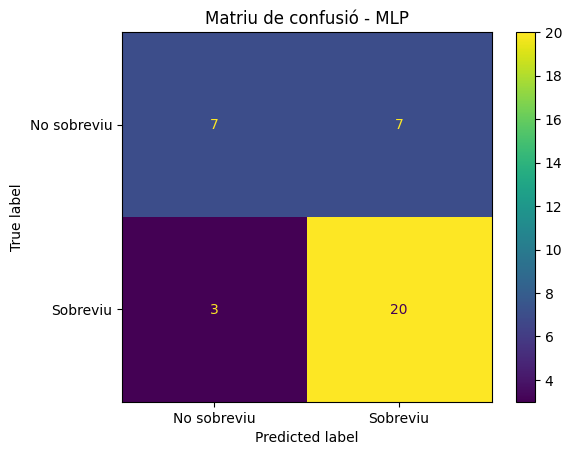

In [14]:
y_pred_sklearn = grid_search.predict(X_val)


cm_mlp = confusion_matrix(y_val, y_pred_sklearn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp,
                               display_labels=['No sobreviu', 'Sobreviu'])
disp.plot()
plt.title("Matriu de confusió - MLP")
plt.show()

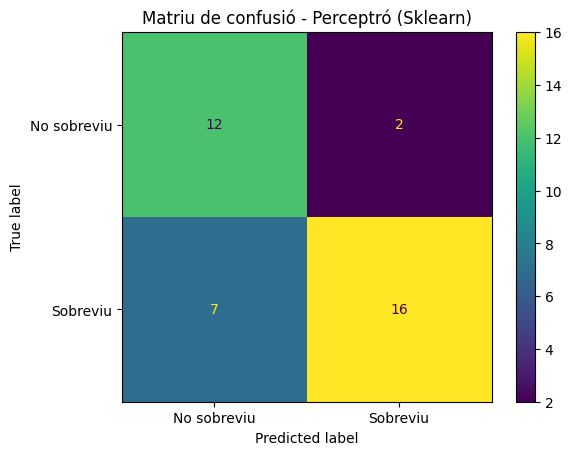

In [11]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model_sklearn = Perceptron(max_iter=2000, random_state=42)
model_sklearn.fit(X_train, y_train)

y_pred_sklearn = model_sklearn.predict(X_val)


cm_sklearn = confusion_matrix(y_val, y_pred_sklearn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_sklearn,
                               display_labels=['No sobreviu', 'Sobreviu'])
disp.plot()
plt.title("Matriu de confusió - Perceptró (Sklearn)")
plt.show()